In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

INPUT_PATH = "/Users/antonio/Desktop/Serie_Temporali/output/entsoe_data_processed.csv"
INPUT_RAW_PATH = "/Users/antonio/Desktop/Serie_Temporali/entsoe_data_2024_2025.csv"
OUTPUT_PATH = "/Users/antonio/Desktop/Serie_Temporali/Analisi_Descrittiva/Diagrammi"
Path(OUTPUT_PATH).mkdir(parents=True, exist_ok=True)

FUSI_ORARI = {
    "AT": "Europe/Vienna", "BE": "Europe/Brussels", "CH": "Europe/Zurich",
    "CZ": "Europe/Prague", "DE_LU": "Europe/Berlin", "DK_1": "Europe/Copenhagen",
    "EE": "Europe/Tallinn", "ES": "Europe/Madrid", "FR": "Europe/Paris",
    "HR": "Europe/Zagreb", "HU": "Europe/Budapest", "IT_NORD": "Europe/Rome",
    "LT": "Europe/Vilnius", "LV": "Europe/Riga", "NL": "Europe/Amsterdam",
    "NO_3": "Europe/Oslo", "PL": "Europe/Warsaw", "PT": "Europe/Lisbon",
    "RO": "Europe/Bucharest", "SE_4": "Europe/Stockholm", "SI": "Europe/Ljubljana",
    "SK": "Europe/Bratislava",
}

def aggiungi_temporalita_locale(df):
    """Aggiunge ora, mese e anno locali in base al fuso della zona di mercato."""
    df = df.copy()
    datetime_utc = pd.to_datetime(df["datetime"], utc=True)
    df["ora_locale"] = -1
    df["mese_locale"] = -1
    df["anno_locale"] = -1

    for paese, fuso in FUSI_ORARI.items():
        mask = df["country"].eq(paese)
        if mask.any():
            datetime_locale = datetime_utc.loc[mask].dt.tz_convert(fuso).dt.tz_localize(None)
            df.loc[mask, "ora_locale"] = datetime_locale.dt.hour.to_numpy()
            df.loc[mask, "mese_locale"] = datetime_locale.dt.month.to_numpy()
            df.loc[mask, "anno_locale"] = datetime_locale.dt.year.to_numpy()

    return df

In [37]:
#Inserimento delle fonti principali
FONTI = {
    "solar": ("Solare", "#F2B705"),
    "wind_onshore": ("Eolico onshore", "#4C9BE8"),
    "wind_offshore": ("Eolico offshore", "#1B5E9E"),
    "hydro_total": ("Idroelettrico", "#2BB3A3"),
    "nuclear": ("Nucleare", "#8E5BD1"),
    "fossil_gas": ("Gas", "#E8743B"),
    "fossil_hard_coal": ("Carbone", "#4A4A4A"),
    "fossil_brown_coal_lignite": ("Lignite", "#8B5A2B"),
    "biomass": ("Biomassa", "#6BAA3C"),
    "waste": ("Rifiuti", "#A9A9A9"),
}

# Mappatura dei codici ISO/ENTSO-E nei nomi estesi
MAPPA_PAESI = {
    "AT": "Austria",
    "BE": "Belgio",
    "CH": "Svizzera",
    "CZ": "Repubblica Ceca",
    "DE_LU": "Germania / Lussemburgo",
    "DK_1": "Danimarca (DK1)",
    "EE": "Estonia",
    "ES": "Spagna",
    "FR": "Francia",
    "HR": "Croazia",
    "HU": "Ungheria",
    "IT_NORD": "Italia (Nord)",
    "LT": "Lituania",
    "LV": "Lettonia",
    "NL": "Paesi Bassi",
    "NO_3": "Norvegia (NO3)",
    "PL": "Polonia",
    "PT": "Portogallo",
    "RO": "Romania",
    "SE_4": "Svezia (SE4)",
    "SI": "Slovenia",
    "SK": "Slovacchia",
}

In [ ]:
# Carico il dataset elaborato e seleziono l'anno completo comune a tutte le zone
dati = aggiungi_temporalita_locale(
    pd.read_csv(INPUT_PATH, usecols=["datetime", "country", *FONTI])
)
dati = dati.loc[dati["anno_locale"] == 2024].copy()

print("Dimensioni del dataset comparativo:", dati.shape)
dati.head()

Grafico salvato in: /Users/antonio/Desktop/Serie_Temporali/Analisi_Descrittiva/Diagrammi/mix_produzione_fonti_separate.png


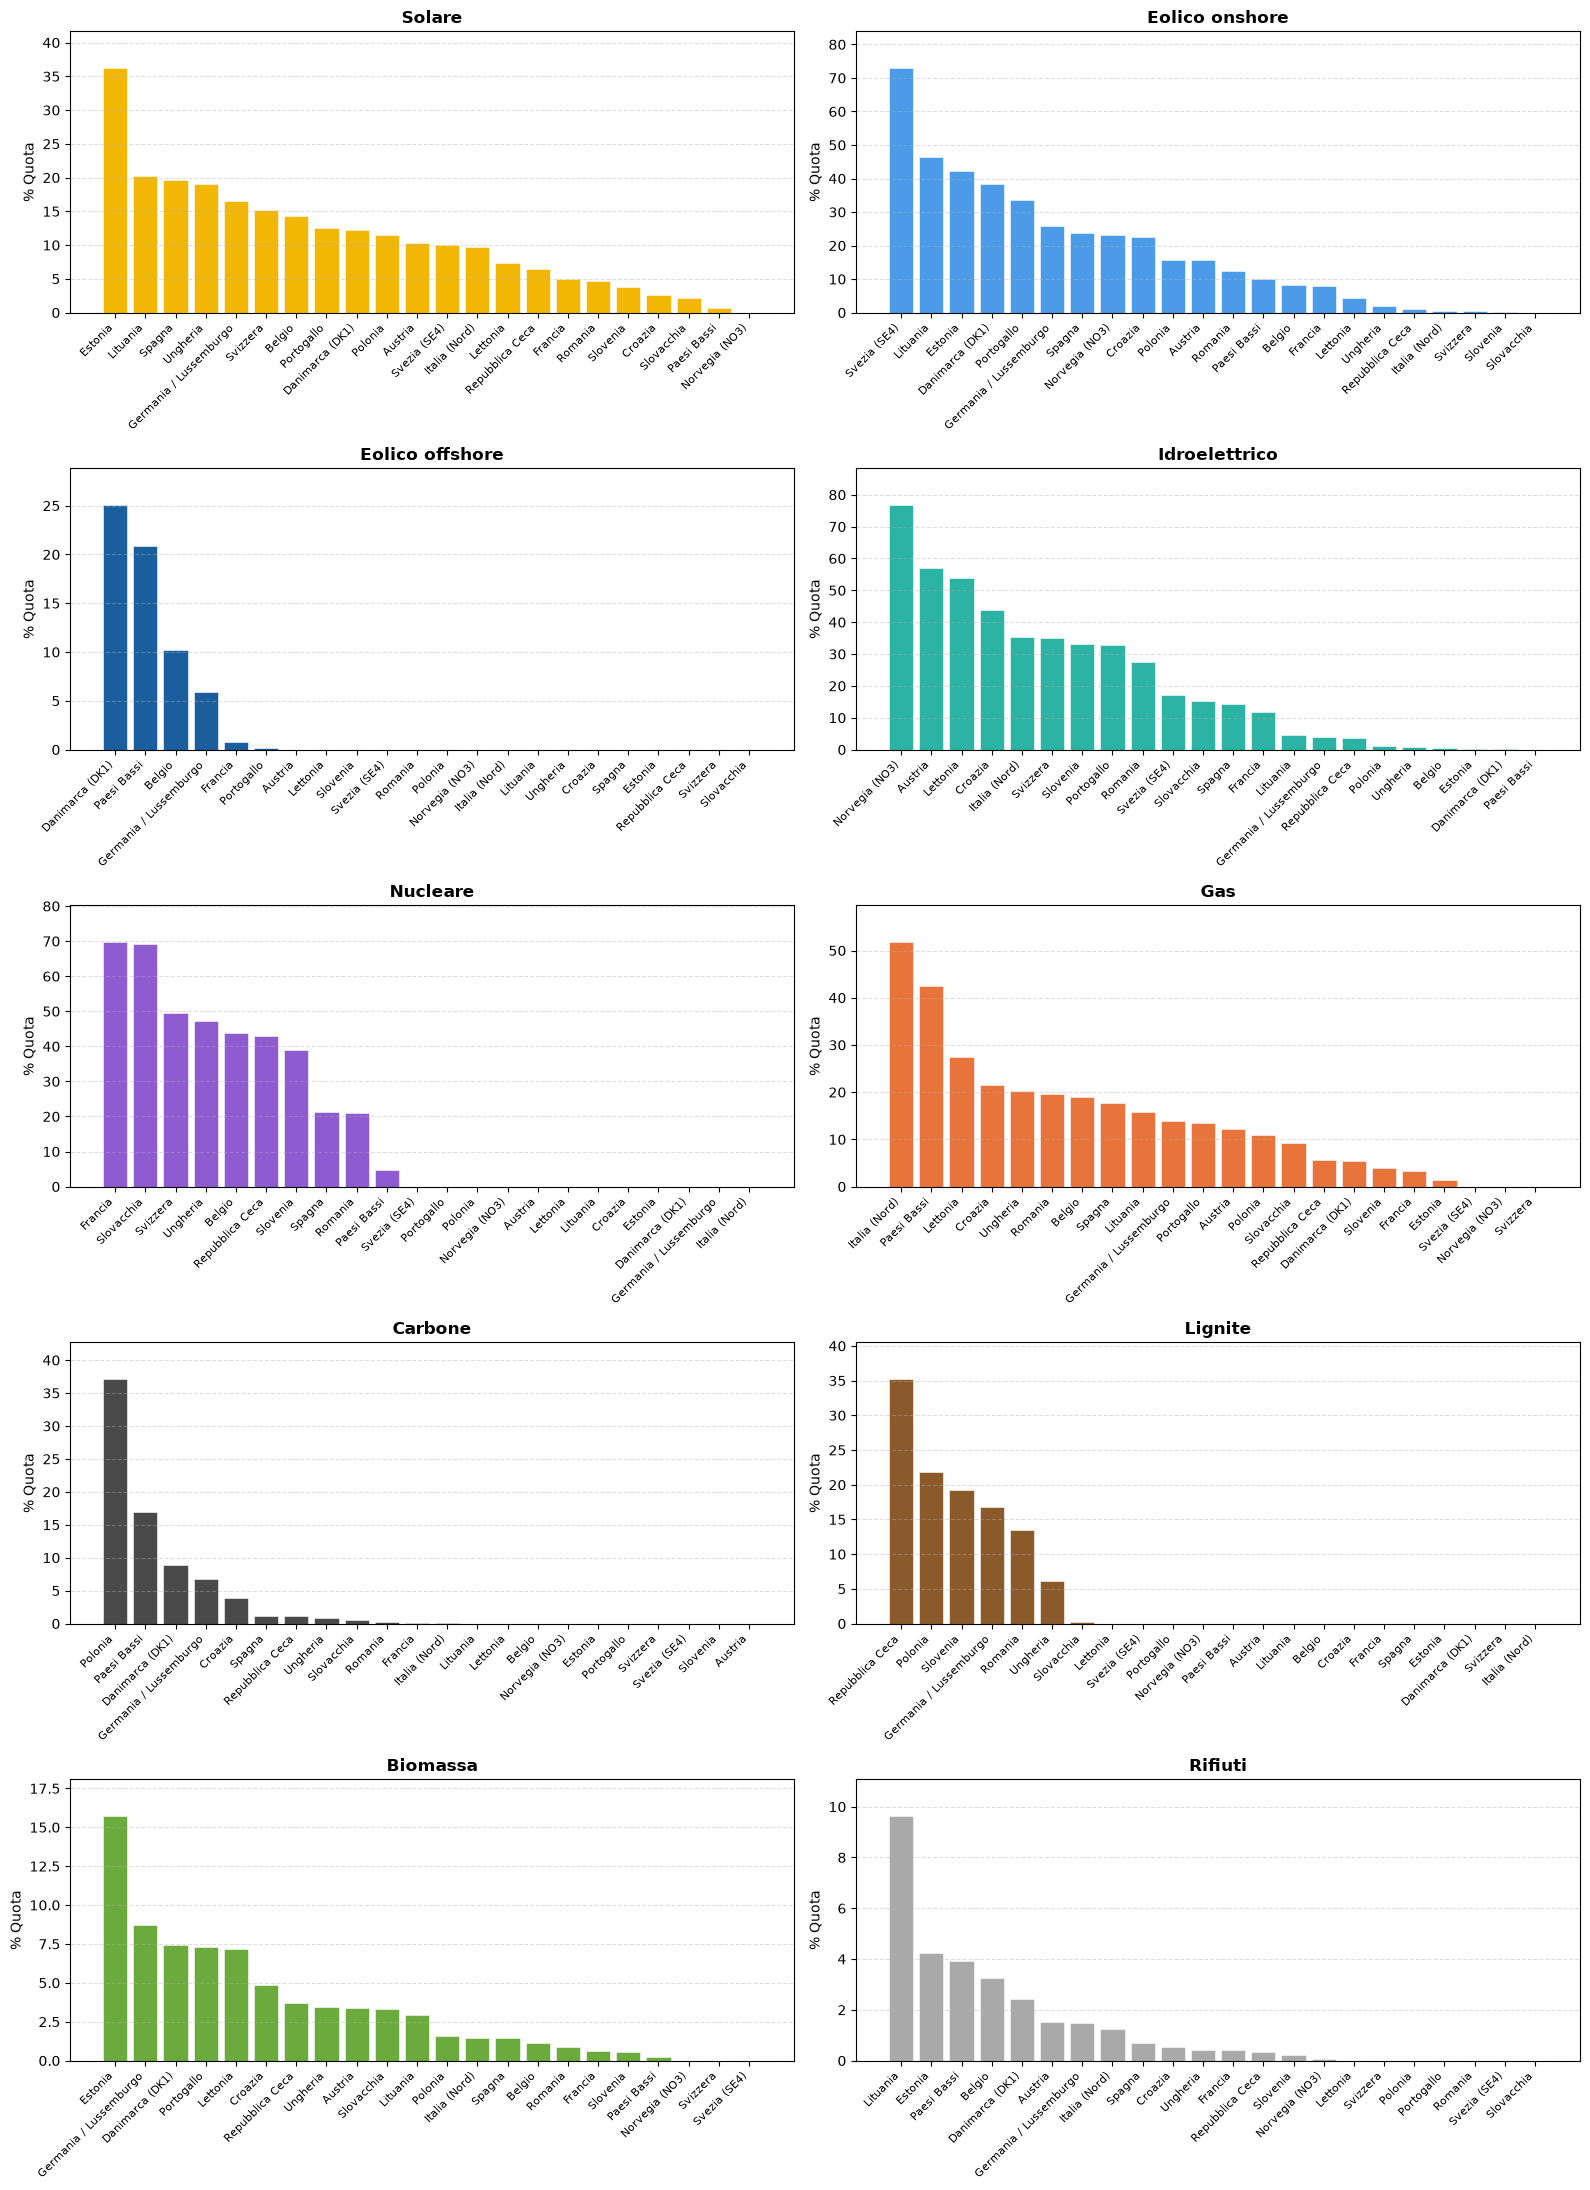

In [39]:
def analizza_e_plotta_fonti_separate(df_dati, dizionario_fonti, mappa_paesi, output_dir=None):
    """
    Calcola la quota percentuale di ogni fonte sul totale per paese
    e genera un sotto-grafico (subplot) separato per ciascuna fonte con nomi estesi.
    """
    # 1. Calcolo delle quote percentuali
    chiavi_fonti = list(dizionario_fonti.keys())
    totali = df_dati.groupby("country")[chiavi_fonti].sum()
    quote = totali.div(totali.sum(axis=1), axis=0) * 100

    # 2. Conversione sigle paesi nei nomi estesi
    quote = quote.rename(index=mappa_paesi)

    # 3. Creazione griglia 5x2 di sotto-grafici
    fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(16, 22))
    axes = axes.flatten()

    # 4. Generazione degli istogrammi separati
    for i, (colonna, (nome, colore)) in enumerate(dizionario_fonti.items()):
        ax = axes[i]
        
        # Ordina i paesi in modo decrescente per la fonte specifica
        quote_fonte = quote[colonna].sort_values(ascending=False)
        
        ax.bar(
            quote_fonte.index,
            quote_fonte.values,
            color=colore,
            edgecolor="white",
            linewidth=0.4,
        )
        
        ax.set_title(nome, fontsize=12, fontweight="bold")
        ax.set_ylabel("% Quota")
        ax.set_ylim(0, max(quote_fonte.max() * 1.15, 5))
        ax.set_xticks(range(len(quote_fonte.index)))
        ax.set_xticklabels(quote_fonte.index, rotation=45, ha="right", fontsize=8)
        ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    
    # 5. Salvataggio facoltativo e visualizzazione
    if output_dir:
        plt.savefig(
            f"{output_dir}/mix_produzione_fonti_separate.png",
            dpi=300,
            bbox_inches="tight",
        )
        print(f"Grafico salvato in: {output_dir}/mix_produzione_fonti_separate.png")
        
    plt.show()

# Esecuzione
analizza_e_plotta_fonti_separate(dati, FONTI, MAPPA_PAESI, OUTPUT_PATH)

In [ ]:
def analizza_profilo_temporale(input_path, dizionario_fonti, output_dir=None):
    """
    Visualizza i profili orari e mensili medi sulle zone, usando l'ora locale.
    Per confronti omogenei considera l'anno completo 2024.
    """
    df = aggiungi_temporalita_locale(pd.read_csv(input_path))
    df = df.loc[df["anno_locale"] == 2024].copy()

    chiavi_fonti = list(dizionario_fonti.keys())
    nomi_italiani = {k: v[0] for k, v in dizionario_fonti.items()}
    colori_dict = {nome: colore for nome, colore in dizionario_fonti.values()}

    profilo_orario = (
        df.groupby("ora_locale")[chiavi_fonti].mean().rename(columns=nomi_italiani)
    )

    fig, ax = plt.subplots(figsize=(14, 6))
    for colonna in profilo_orario.columns:
        ax.plot(
            profilo_orario.index, profilo_orario[colonna],
            label=colonna, color=colori_dict.get(colonna), linewidth=2.5,
        )

    ax.set_title("Profilo di Produzione Orario Medio (2024, ora locale)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Ora locale della giornata")
    ax.set_ylabel("Produzione media (MW)")
    ax.set_xticks(range(0, 24))
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
    plt.tight_layout()

    if output_dir:
        plt.savefig(f"{output_dir}/profilo_orario_medio.png", dpi=300, bbox_inches="tight")
    plt.show()

    profilo_mensile = (
        df.groupby("mese_locale")[chiavi_fonti].mean().rename(columns=nomi_italiani)
    )
    nomi_mesi = ["Gen", "Feb", "Mar", "Apr", "Mag", "Giu", "Lug", "Ago", "Set", "Ott", "Nov", "Dic"]

    fig, ax = plt.subplots(figsize=(14, 6))
    for colonna in profilo_mensile.columns:
        ax.plot(
            nomi_mesi,
            profilo_mensile[colonna],
            label=colonna, color=colori_dict.get(colonna), linewidth=2.5, marker="o",
        )

    ax.set_title("Stagionalità Mensile della Produzione Energetica (2024)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Mese")
    ax.set_ylabel("Produzione media (MW)")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
    plt.tight_layout()

    if output_dir:
        plt.savefig(f"{output_dir}/stagionalita_mensile.png", dpi=300, bbox_inches="tight")
    plt.show()

analizza_profilo_temporale(INPUT_PATH, FONTI, OUTPUT_PATH)

In [ ]:
def analizza_profilo_temporale_paese(
    input_path,
    dizionario_fonti,
    mappa_paesi=None,
    codice_paese="IT_NORD",
    output_dir=None,
):
    """Visualizza profili orari e mensili locali per una zona nel 2024."""
    df = aggiungi_temporalita_locale(pd.read_csv(input_path))
    df_paese = df.loc[
        (df["country"] == codice_paese) & (df["anno_locale"] == 2024)
    ].copy()

    nome_paese = (
        mappa_paesi.get(codice_paese, codice_paese)
        if mappa_paesi else codice_paese
    )
    chiavi_fonti = list(dizionario_fonti.keys())
    nomi_italiani = {k: v[0] for k, v in dizionario_fonti.items()}
    colori_dict = {nome: colore for nome, colore in dizionario_fonti.values()}

    profilo_orario = (
        df_paese.groupby("ora_locale")[chiavi_fonti].mean().rename(columns=nomi_italiani)
    )
    fig, ax = plt.subplots(figsize=(14, 6))
    for colonna in profilo_orario.columns:
        if profilo_orario[colonna].sum() > 0:
            ax.plot(
                profilo_orario.index, profilo_orario[colonna],
                label=colonna, color=colori_dict.get(colonna), linewidth=2.5,
            )

    ax.set_title(f"Profilo di Produzione Orario Medio - {nome_paese} (2024)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Ora locale della giornata")
    ax.set_ylabel("Produzione media (MW)")
    ax.set_xticks(range(0, 24))
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
    plt.tight_layout()

    if output_dir:
        plt.savefig(f"{output_dir}/profilo_orario_{codice_paese}.png", dpi=300, bbox_inches="tight")
    plt.show()

    profilo_mensile = (
        df_paese.groupby("mese_locale")[chiavi_fonti].mean().rename(columns=nomi_italiani)
    )
    nomi_mesi = ["Gen", "Feb", "Mar", "Apr", "Mag", "Giu", "Lug", "Ago", "Set", "Ott", "Nov", "Dic"]

    fig, ax = plt.subplots(figsize=(14, 6))
    for colonna in profilo_mensile.columns:
        if profilo_mensile[colonna].sum() > 0:
            ax.plot(
                nomi_mesi, profilo_mensile[colonna],
                label=colonna, color=colori_dict.get(colonna),
                linewidth=2.5, marker="o",
            )

    ax.set_title(f"Stagionalità Mensile della Produzione Energetica - {nome_paese} (2024)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Mese")
    ax.set_ylabel("Produzione media (MW)")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
    plt.tight_layout()

    if output_dir:
        plt.savefig(f"{output_dir}/stagionalita_mensile_{codice_paese}.png", dpi=300, bbox_inches="tight")
    plt.show()

analizza_profilo_temporale_paese(
    INPUT_PATH, FONTI, MAPPA_PAESI, codice_paese="IT_NORD", output_dir=OUTPUT_PATH
)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def matrice_pearson_per_paese(input_path, dizionario_fonti, mappa_paesi=None, output_dir=None):
    """
    Mostra una heatmap della correlazione di Pearson tra il prezzo dell'energia 
    e la produzione delle diverse fonti per ciascun paese.
    """
    df = aggiungi_temporalita_locale(pd.read_csv(input_path))
    df = df.loc[df["anno_locale"] == 2024].copy()
    fonti = list(dizionario_fonti.keys())
    nomi_fonti = {colonna: etichetta[0] for colonna, etichetta in dizionario_fonti.items()}

    correlazioni = {}
    for paese, gruppo in df.groupby("country"):
        correlazioni[paese] = (
            gruppo[["price"] + fonti]
            .corr(method="pearson")["price"]
            .drop("price")
        )

    matrice = pd.DataFrame(correlazioni).rename(index=nomi_fonti)

    if mappa_paesi:
        matrice = matrice.rename(columns=mappa_paesi)

    # Crea una matrice di testo sostituendo i NaN con un trattino "-"
    annot_text = matrice.map(lambda x: f"{x:.2f}" if pd.notna(x) else "-")

    plt.figure(figsize=(18, 8))
    sns.heatmap(
        matrice,
        annot=annot_text,
        fmt="",  # Usa le stringhe formattate da annot_text
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        cbar_kws={"label": "Correlazione di Pearson"},
    )
    plt.title("Matrice di Correlazione tra Prezzo e Fonti di Produzione per Paese", fontsize=13, fontweight="bold")
    plt.xlabel("Paese")
    plt.ylabel("Fonte di Produzione")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if output_dir:
        plt.savefig(
            f"{output_dir}/matrice_correlazione_prezzo_paesi.png",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()

    return matrice

# Esecuzione
matrice_pearson = matrice_pearson_per_paese(INPUT_PATH, FONTI, MAPPA_PAESI, OUTPUT_PATH)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def matrice_spearman_per_paese(
    input_path,
    dizionario_fonti,
    mappa_paesi=None,
    output_dir=None,
):
    """
    Calcola e visualizza la correlazione di Spearman tra il prezzo dell'energia
    e la produzione delle diverse fonti per ciascun paese.
    """
    df = aggiungi_temporalita_locale(pd.read_csv(input_path))
    df = df.loc[df["anno_locale"] == 2024].copy()
    fonti = list(dizionario_fonti.keys())
    nomi_fonti = {
        colonna: etichetta[0]
        for colonna, etichetta in dizionario_fonti.items()
    }

    correlazioni = {}

    for paese, gruppo in df.groupby("country"):
        correlazioni[paese] = (
            gruppo[["price"] + fonti]
            .corr(method="spearman")["price"]
            .drop("price")
        )

    matrice = pd.DataFrame(correlazioni)

    if mappa_paesi:
        matrice = matrice.rename(columns=mappa_paesi)

    matrice = matrice.rename(index=nomi_fonti)

    # Gestione delle etichette con trattino "-" al posto dei NaN
    annot_text = matrice.map(lambda x: f"{x:.2f}" if pd.notna(x) else "-")

    plt.figure(figsize=(18, 8))
    sns.heatmap(
        matrice,
        annot=annot_text,
        fmt="",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        cbar_kws={"label": "Correlazione di Spearman"},
    )
    plt.title(
        "Matrice di Correlazione di Spearman tra Prezzo e Fonti di Produzione per Paese",
        fontsize=13,
        fontweight="bold",
    )
    plt.xlabel("Paese")
    plt.ylabel("Fonte di Produzione")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if output_dir:
        plt.savefig(
            f"{output_dir}/matrice_spearman_prezzo_paesi.png",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    return matrice


# Esecuzione
matrice_spearman = matrice_spearman_per_paese(
    INPUT_PATH, FONTI, MAPPA_PAESI, OUTPUT_PATH
)

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# =============================================================================
# CONFIGURAZIONI GLOBALI
# =============================================================================
INPUT_RAW_PATH = "/Users/antonio/Desktop/Serie_Temporali/entsoe_data_2024_2025.csv"
OUTPUT_PATH = "/Users/antonio/Desktop/Serie_Temporali/Analisi_Descrittiva/Diagrammi"

MAPPA_PAESI = {
    "AT": "Austria",
    "BE": "Belgio",
    "CH": "Svizzera",
    "CZ": "Repubblica Ceca",
    "DE_LU": "Germania / Lussemburgo",
    "DK_1": "Danimarca (DK1)",
    "EE": "Estonia",
    "ES": "Spagna",
    "FR": "Francia",
    "HR": "Croazia",
    "HU": "Ungheria",
    "IT_NORD": "Italia (Nord)",
    "LT": "Lituania",
    "LV": "Lettonia",
    "NL": "Paesi Bassi",
    "NO_3": "Norvegia (NO3)",
    "PL": "Polonia",
    "PT": "Portogallo",
    "RO": "Romania",
    "SE_4": "Svezia (SE4)",
    "SI": "Slovenia",
    "SK": "Slovacchia",
}


# =============================================================================
# FUNZIONE MAPPA GEOGRAFICA ELEGANTE
# =============================================================================
def mappa_prezzo_geografica_elegante(
    input_path, mappa_paesi=None, output_dir=None
):
    """Genera una mappa coropletica europea ad alta risoluzione con proiezione EPSG:3035.

    - Verde: prezzo più basso
    - Rosso: prezzo più alto
    """
    # 1. Caricamento dati e calcolo prezzo medio per paese
    df = pd.read_csv(input_path)
    prezzi_medi = df.groupby("country")["price"].mean().reset_index()

    mappa_iso3 = {
        "AT": "AUT",
        "BE": "BEL",
        "CH": "CHE",
        "CZ": "CZE",
        "DE_LU": "DEU",
        "DK_1": "DNK",
        "EE": "EST",
        "ES": "ESP",
        "FR": "FRA",
        "HR": "HRV",
        "HU": "HUN",
        "IT_NORD": "ITA",
        "LT": "LTU",
        "LV": "LVA",
        "NL": "NLD",
        "NO_3": "NOR",
        "PL": "POL",
        "PT": "PRT",
        "RO": "ROU",
        "SE_4": "SWE",
        "SI": "SVN",
        "SK": "SVK",
    }
    prezzi_medi["iso_a3"] = prezzi_medi["country"].map(mappa_iso3)

    # 2. Caricamento GeoJSON ad alta risoluzione (50m)
    url_geojson = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson"

    try:
        world = gpd.read_file(url_geojson)
    except Exception:
        world = gpd.read_file(
            "/Users/antonio/Desktop/Serie_Temporali/Analisi_Descrittiva/confini/naturalearth_lowres.shp"
        )
        col_iso = "iso_a3"
        col_cont = "continent"
        col_name = "name"
    else:
        col_iso = "ISO_A3_EH" if "ISO_A3_EH" in world.columns else "ADM0_A3"
        col_cont = "CONTINENT"
        col_name = "NAME"

    # Filtra Europa (esclusa la Russia)
    europa = world[
        (world[col_cont] == "Europe") & (world[col_name] != "Russia")
    ].copy()
    europa["iso_a3"] = europa[col_iso]
    # Natural Earth low-resolution usa -99 per questi due codici.
    if col_iso == "iso_a3":
        europa.loc[europa[col_name].eq("France"), "iso_a3"] = "FRA"
        europa.loc[europa[col_name].eq("Norway"), "iso_a3"] = "NOR"

    # Join dati
    europa_mappa = europa.merge(prezzi_medi, on="iso_a3", how="left")

    # 3. Riproiezione cartesiana specifica per l'Europa (EPSG:3035 - ETRS89)
    europa_mappa = europa_mappa.to_crs(epsg=3035)

    # 4. Rendering grafico
    fig, ax = plt.subplots(figsize=(14, 11), facecolor="#f8fafc")
    ax.set_facecolor("#f8fafc")

    europa_mappa.plot(
        column="price",
        cmap="RdYlGn_r",
        linewidth=0.8,
        ax=ax,
        edgecolor="white",  # bordi bianchi definiti
        legend=True,
        legend_kwds={
            "label": "Prezzo Medio (€/MWh)",
            "orientation": "horizontal",
            "shrink": 0.5,
            "pad": 0.03,
            "aspect": 30,
        },
        missing_kwds={"color": "#e2e8f0", "label": "Dati non disponibili"},
    )

    # Inquadratura ottimizzata in metri per la proiezione EPSG:3035
    ax.set_xlim(2400000, 6600000)
    ax.set_ylim(1300000, 5300000)
    ax.set_axis_off()

    plt.title(
        "Mappa Geografica dei Prezzi Medi dell'Elettricità in Europa",
        fontsize=16,
        fontweight="bold",
        pad=15,
        color="#1e293b",
    )

    plt.tight_layout()

    # 5. Salvataggio
    if output_dir:
        plt.savefig(
            f"{output_dir}/mappa_geografica_prezzi_europa.png",
            dpi=300,
            bbox_inches="tight",
            facecolor=fig.get_facecolor(),
        )

    plt.show()


# =============================================================================
# ESECUZIONE
# =============================================================================
mappa_prezzo_geografica_elegante(INPUT_RAW_PATH, MAPPA_PAESI, OUTPUT_PATH)